# <font color="gold">0-1. Extract RateMyProfessor Teacher Review Data</font>

## <font color='cornflowerblue'>Teacher review - Dataset Info</font>

-----------------------------------------
Category:  &ensp;&emsp; Teacher review  
Source:    &ensp; &ensp;&ensp; &ensp;  He (2020) – RMP V2   (N = 19145 after removing null comments)  
Reference: &ensp;&ensp; He, Jibo (2020), “Big Data Set from RateMyProfessor.com for Professors' Teaching Evaluation”, Mendeley Data, V2, doi: 10.17632/fvtfjyvw7d.   
URL:     &ensp; &ensp; &ensp; &ensp;  &ensp;  https://data.mendeley.com/datasets/fvtfjyvw7d/2  
Lisence:  &ensp; &ensp; &ensp;  CC BY 4.0  


-----------------------------------------

In [1]:
import pandas as pd
import os, glob

file_1_path = '../../data/0_raw/data1_He_2020_RMP_v2'

outfilename = '../../data/1_processed/1_He_2020_RMP_v2.csv'

print(f'Input:    {file_1_path}\n\nOutput:   {outfilename}')

Input:    ../../data/0_raw/data1_He_2020_RMP_v2

Output:   ../../data/1_processed/1_He_2020_RMP_v2.csv


In [2]:
pattern = os.path.join(file_1_path, '*.csv')

# Iterate through all CSV files in the folder
dflist = []
line_counter = 0
for file_path in glob.glob(pattern):
    tempdf = pd.read_csv(file_path)
    dflist.append(tempdf)
    line_counter += len(tempdf)
    
df1 = pd.concat(dflist, ignore_index=True, sort=False, copy=True)
print(line_counter, len(df1))

if len(df1)==line_counter:
    print(f"\n\033[032mAll good!\033[0m\n{list(df1.columns.values)}\n")
    display(df1)
else:
    raise ValueError(f"\033[45mNot the same length!  Should be {line_counter} but df has {len(df1)}, check!!\033[0m")

19685 19685

All good!
['professor_name', 'school_name', 'department_name', 'local_name', 'state_name', 'year_since_first_review', 'star_rating', 'take_again', 'diff_index', 'tag_professor', 'num_student', 'post_date', 'name_onlines', 'student_star', 'student_difficult', 'attence', 'for_credits', 'would_take_agains', 'grades', 'stu_tags', 'help_useful', 'help_not_useful', 'comments']



,professor_name,school_name,department_name,local_name,state_name,year_since_first_review,star_rating,take_again,diff_index,tag_professor,...,student_star,student_difficult,attence,for_credits,would_take_agains,grades,stu_tags,help_useful,help_not_useful,comments
0,Keiji Shinohara,Wesleyan University,Fine Arts department,Middletown,CT,6.0,5.0,NaN,2.0,Respected (1) Clear grading criteria (1) Giv...,...,5.0,2.0,Mandatory,Yes,Yes,NaN,RESPECTED CLEAR GRADING CRITERIA GIVES GOOD ...,0,0,Keiji is literally the best teacher I\'ve had ...
1,Keiji Shinohara,Wesleyan University,Fine Arts department,Middletown,CT,6.0,5.0,NaN,2.0,Respected (1) Clear grading criteria (1) Giv...,...,5.0,3.0,NaN,NaN,NaN,NaN,NaN,0,0,I have taken several classes with Keiji. He is...
2,Keiji Shinohara,Wesleyan University,Fine Arts department,Middletown,CT,6.0,5.0,NaN,2.0,Respected (1) Clear grading criteria (1) Giv...,...,5.0,1.0,NaN,NaN,NaN,NaN,NaN,0,0,Keiji is amazing. He is an incredible and acco...
3,Eddie Perez,Chaffey College (all campuses),Sociology department,Rancho Cucamonga,CA,0.0,4.5,NaN,2.0,NaN,...,4.0,2.0,NaN,NaN,NaN,NaN,NaN,0,0,He is really cute and funny. He truly cares ab...
4,Eddie Perez,Chaffey College (all campuses),Sociology department,Rancho Cucamonga,CA,0.0,4.5,NaN,2.0,NaN,...,5.0,2.0,NaN,NaN,NaN,NaN,NaN,0,0,No Comments
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19680,Gladys Francis,Wesleyan College,Languages department,Macon,GA,2.0,4.3,NaN,4.3,NaN,...,5.0,4.0,NaN,NaN,NaN,NaN,NaN,0,0,She is absolutely amazing and her class is the...
19681,Ben Epstein,Brooklyn College,Political Science department,Brooklyn,NY,2.0,5.0,NaN,2.0,NaN,...,5.0,3.0,NaN,NaN,NaN,NaN,NaN,0,0,Great Professor. One of the best at Brooklyn c...
19682,Ben Epstein,Brooklyn College,Political Science department,Brooklyn,NY,2.0,5.0,NaN,2.0,NaN,...,5.0,2.0,NaN,NaN,NaN,NaN,NaN,0,0,this guy is a great prof. makes the class and ...
19683,Ben Epstein,Brooklyn College,Political Science department,Brooklyn,NY,2.0,5.0,NaN,2.0,NaN,...,5.0,1.0,NaN,NaN,NaN,NaN,NaN,0,0,"Epstein used to teach in Murrow, I had him a f..."


In [3]:
# check descrepency between average rating ("star_rating") and individual rating ("studenet_star")

df1.loc[:, "rating_diff"] = df1.star_rating - df1.student_star
df1 = df1.sort_values(by=['rating_diff'], ascending=False).reset_index()
df1.filter(regex="star|rating_diff|comments")

,star_rating,student_star,comments,rating_diff
0,4.6,1.0,"Never trust yourself, you would be surprised b...",3.6
1,4.6,1.0,"This class is an easy A, but don\'t expect to ...",3.6
2,4.6,1.0,Overall terrible experience.,3.6
3,4.6,1.0,He did not teach me a single thing. I went int...,3.6
4,4.6,1.0,Not a bad professor as he is very passionate a...,3.6
...,...,...,...,...
19680,4.5,NaN,NaN,NaN
19681,3.8,NaN,NaN,NaN
19682,1.3,NaN,NaN,NaN
19683,4.0,NaN,NaN,NaN


In [4]:
df1 = df1[['department_name', 'professor_name', 'student_star', 'comments']]
df1 = df1.rename(columns={'department_name': 'department', 'professor_name': 'teacher_name', 'student_star': 'rating', 'comments': 'review_text'}).fillna('')

df1.department = df1.department.str.replace('department', '').str.strip()
print(sorted(df1.department.unique()))
df1

['Academic Learning Skills', 'Academic Skills Development', 'Accounting', 'Administration', 'Administration Of Justice', 'Advertising Design', 'Advisor', 'Aerospace Studies', 'African Studies', 'Agribusiness', 'Agriculture', 'Air Conditioning & Refrig.', 'Allied Health', 'American Studies', 'Anatomy', 'Animal Science', 'Anthropology', 'Applied Linguistics', 'Applied Mathematics', 'Archaeology', 'Architecture', 'Art', 'Art & Art History', 'Art & Design', 'Art History', 'Art Studio', 'Art, Media, & Design', 'Arts & Sciences', 'Arts, Humanities & Comm', 'Asian Studies', 'Automotive Technology', 'Aviation', 'Aviation Pilot Instructor', 'Behavioral Sciences', 'Biochemistry', 'Bioengineering', 'Biological Sciences', 'Biology', 'Biomedical', 'Black Studies', 'Business', 'Business Administration', 'Business Law', 'Business Technology', 'Canadian Studies', 'Ceramics', 'Chemical Engineering', 'Chemistry', 'Child & Family Studies', 'Child Development', 'Chinese', 'Chiropractic Education', 'Civil 

,department,teacher_name,rating,review_text
0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b..."
1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ..."
2,Music,Marcos Krieger,1.0,Overall terrible experience.
3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...
4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...
...,...,...,...,...
19680,Languages,Jeremy Crowe,,
19681,Biology,Gary King,,
19682,Engineering,Sandra Yost,,
19683,English,Rachael Rettich,,


,rating,count
9,,13
3,1.0,2099
7,1.5,815
4,2.0,1200
8,2.5,748
5,3.0,1195
6,3.5,997
2,4.0,2387
1,4.5,2559
0,5.0,7672


<Axes: xlabel='Count', ylabel='rating'>

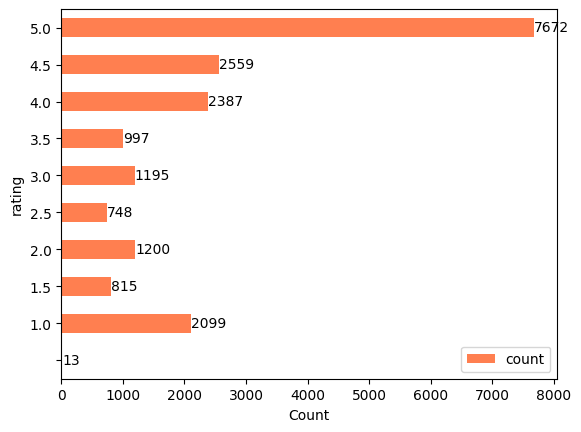

In [5]:
rating_df = df1.rating.astype(str).value_counts().reset_index().sort_values(by='rating', ascending=True)

display(rating_df)

ax1 = rating_df.plot.barh(x='rating', y='count', xlabel='Count', color='coral', table=False)
ax1.bar_label(ax1.containers[0])
ax1 

In [6]:
print(len(df1))
df1 = df1.loc[(df1.review_text.str.len() > 0) & (~df1.review_text.str.lower().isin(['no comment', 'no comments'])) & (~df1.review_text.str.fullmatch(r'([.]+|[,]+)'))]
print(len(df1))

df1.loc[:, 'source'] = f'data1_{len(df1)}'
df1

19685
19145


/tmp/ipykernel_45040/3886637990.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1.loc[:, 'source'] = f'data1_{len(df1)}'


,department,teacher_name,rating,review_text,source
0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145
1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145
2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145
3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145
4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145
...,...,...,...,...,...
19667,Nursing,Crystal Porter,5.0,Took her back in the spring. Best Damn teacher...,data1_19145
19668,Chemistry,Henry Ajie,5.0,I had 2 semesters class with him. He is trying...,data1_19145
19669,Chemistry,C Davis,5.0,He is a great professor; and every helpful per...,data1_19145
19670,Economics,Joseph Hotz,5.0,Have to say that his problems sets really take...,data1_19145


<br>

## <font color='cornflowerblue'>3. Merge file</font>

In [7]:
output = df1.copy().reset_index()
output = output.fillna('')

output

/tmp/ipykernel_45040/1474450931.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  output = output.fillna('')


,index,department,teacher_name,rating,review_text,source
0,0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145
1,1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145
2,2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145
3,3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145
4,4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145
...,...,...,...,...,...,...
19140,19667,Nursing,Crystal Porter,5.0,Took her back in the spring. Best Damn teacher...,data1_19145
19141,19668,Chemistry,Henry Ajie,5.0,I had 2 semesters class with him. He is trying...,data1_19145
19142,19669,Chemistry,C Davis,5.0,He is a great professor; and every helpful per...,data1_19145
19143,19670,Economics,Joseph Hotz,5.0,Have to say that his problems sets really take...,data1_19145


In [8]:
output.loc[output.review_text.str.fullmatch(r'([.]+|[,]+)')]

,index,department,teacher_name,rating,review_text,source


In [9]:
output[['department','source']].value_counts()

department                    source     
English                       data1_19145    2171
Mathematics                   data1_19145    1660
Psychology                    data1_19145    1021
Biology                       data1_19145     965
Chemistry                     data1_19145     869
                                             ... 
Counseling & Career Planning  data1_19145       1
Communication & Theatre       data1_19145       1
Psychology & Sociology        data1_19145       1
Recreation, Parks, & Tourism  data1_19145       1
Korean                        data1_19145       1
Name: count, Length: 265, dtype: int64

,rating,count
3,1.0,2053
7,1.5,794
4,2.0,1167
8,2.5,729
5,3.0,1155
6,3.5,961
2,4.0,2316
1,4.5,2456
0,5.0,7514


<Axes: xlabel='Count', ylabel='rating'>

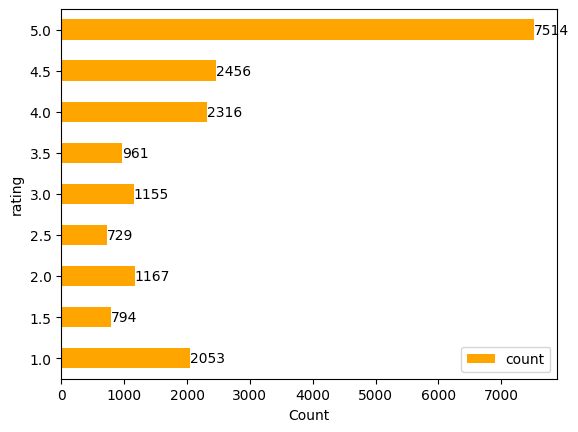

In [10]:
overall_ratingdf = output.rating.value_counts().reset_index().sort_values(by='rating', ascending=True)

display(overall_ratingdf)

ax3 = overall_ratingdf.plot.barh(x='rating', y='count', xlabel='Count', color='orange', table=False)
ax3.bar_label(ax3.containers[0]) 
ax3

In [13]:
idcols = ['source', 'department', 'teacher_name', 'index']

for each in idcols:
    if each == 'source':
        output.loc[:,f'{each}_rank'] = output.source.str[4]
    else:
        output.loc[:,f'{each}_rank'] = output[each].rank(method='dense').astype(int)
    
output

,index,department,teacher_name,rating,review_text,source,source_rank,department_rank,teacher_name_rank,index_rank
0,0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145,1,90,2430,1
1,1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145,1,236,180,2
2,2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145,1,182,1691,3
3,3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145,1,40,401,4
4,4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145,1,37,1575,5
...,...,...,...,...,...,...,...,...,...,...
19140,19667,Nursing,Crystal Porter,5.0,Took her back in the spring. Best Damn teacher...,data1_19145,1,187,499,19141
19141,19668,Chemistry,Henry Ajie,5.0,I had 2 semesters class with him. He is trying...,data1_19145,1,45,947,19142
19142,19669,Chemistry,C Davis,5.0,He is a great professor; and every helpful per...,data1_19145,1,45,328,19143
19143,19670,Economics,Joseph Hotz,5.0,Have to say that his problems sets really take...,data1_19145,1,82,1317,19144


In [14]:
output.insert(loc=0, column='id', value=output.filter(regex='_rank').map(str).apply('_'.join, axis=1))
output.loc[:,'type'] = 'teacher review'

if len(output.id.unique())==len(output):
    print("\033[32mAll good!\n\033[0m")
    output = output.drop(columns=[i for i in output.columns.values if '_rank' in i])
else:
    display(output.loc[output.id.duplicated(keep='first')].sort_values(by='id'))
    raise ValueError("ids not unique, check!!!!")
output

All good!



,id,index,department,teacher_name,rating,review_text,source,type
0,1_90_2430_1,0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145,teacher review
1,1_236_180_2,1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145,teacher review
2,1_182_1691_3,2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145,teacher review
3,1_40_401_4,3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145,teacher review
4,1_37_1575_5,4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145,teacher review
...,...,...,...,...,...,...,...,...
19140,1_187_499_19141,19667,Nursing,Crystal Porter,5.0,Took her back in the spring. Best Damn teacher...,data1_19145,teacher review
19141,1_45_947_19142,19668,Chemistry,Henry Ajie,5.0,I had 2 semesters class with him. He is trying...,data1_19145,teacher review
19142,1_45_328_19143,19669,Chemistry,C Davis,5.0,He is a great professor; and every helpful per...,data1_19145,teacher review
19143,1_82_1317_19144,19670,Economics,Joseph Hotz,5.0,Have to say that his problems sets really take...,data1_19145,teacher review


<br>

## <font color='gold'>4. Write output</font>

In [15]:
print(output.shape)
output.to_csv(outfilename, index=True)
print(f'\n\033[33mCombined file written to {outfilename} :)\n')

(19145, 8)

Combined file written to ../../data/1_processed/1_He_2020_RMP_v2.csv :)

